In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

X_train = pd.read_csv("X_train_update.csv", index_col=0)
y_train = pd.read_csv("Y_train_CVw08PX.csv", index_col=0)
X_test  = pd.read_csv("X_test_update.csv", index_col=0)


# Affiche les premières lignes du DataFrame pour avoir un aperçu des données
display(X_train.head())
display(y_train.head())

# Affiche les dimensions du DataFrame (nombre de lignes et de colonnes)
print(f"Dimension de X_train : {X_train.shape}")
print(f"Dimension de y_train : {y_train.shape}")
print(f"Dimension de X_test  : {X_test.shape}")

# Affiche les types de données de chaque colonne
print(X_train.info())
print(y_train.info())
print(X_test.info())


# Affiche des statistiques descriptives pour les colonnes numériques
display(X_train.describe())
display(y_train.describe())

# Affiche des statistiques descriptives pour les colonnes catégorielles
display(X_train.describe(include="O"))




,designation,description,productid,imageid
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...,NaN,436067568,1008141237
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo...,PILOT STYLE Touch Pen de marque Speedlink est ...,201115110,938777978
3,Peluche Donald - Europe - Disneyland 2000 (Mar...,NaN,50418756,457047496
4,La Guerre Des Tuques,Luc a des id&eacute;es de grandeur. Il veut or...,278535884,1077757786


,prdtypecode
0,10
1,2280
2,50
3,1280
4,2705


Dimension de X_train : (84916, 4)
Dimension de y_train : (84916, 1)
Dimension de X_test  : (13812, 4)
<class 'pandas.DataFrame'>
RangeIndex: 84916 entries, 0 to 84915
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   designation  84916 non-null  str  
 1   description  55116 non-null  str  
 2   productid    84916 non-null  int64
 3   imageid      84916 non-null  int64
dtypes: int64(2), str(2)
memory usage: 2.6 MB
None
<class 'pandas.DataFrame'>
RangeIndex: 84916 entries, 0 to 84915
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   prdtypecode  84916 non-null  int64
dtypes: int64(1)
memory usage: 663.5 KB
None
<class 'pandas.DataFrame'>
RangeIndex: 13812 entries, 84916 to 98727
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   designation  13812 non-null  str  
 1   description  8926 non-

,productid,imageid
count,8.491600e+04,8.491600e+04
mean,2.555468e+09,1.152691e+09
std,1.588656e+09,1.751427e+08
min,1.839120e+05,6.728400e+04
25%,6.760519e+08,1.056269e+09
50%,3.190506e+09,1.213354e+09
75%,3.995599e+09,1.275646e+09
max,4.252012e+09,1.328824e+09


,prdtypecode
count,84916.000000
mean,1773.219900
std,788.179885
min,10.000000
25%,1281.000000
50%,1920.000000
75%,2522.000000
max,2905.000000


C:\Users\loud\AppData\Local\Temp\ipykernel_5272\3080823144.py:30: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(X_train.describe(include="O"))


,designation,description
count,84916,55116
unique,82265,47506
top,5d Broderie Peintures Strass Diamant Bricolage...,<br>Attention !!! Ce produit est un import si...
freq,76,252


In [13]:
X_train['description'].isna().mean()

np.float64(0.3509350416882566)

In [14]:
# 1. Nombre de lignes qui ont un productid dupliqué
doublons_productID = X_train[X_train.duplicated(subset=["productid"], keep=False)]
print('nb de lignes avec doublons productid :', doublons_productID.shape[0])

# 2. Nombre de lignes qui ont un imageid dupliqué
doublons_imageid = X_train[X_train.duplicated(subset=["imageid"], keep=False)]
print('nb de lignes avec doublons imageid :', doublons_imageid.shape[0])

# 2. Nombre de lignes qui ont un description dupliqué
doublons_description = X_train[X_train.duplicated(subset=["description"], keep=False)]
print('nb de lignes avec doublons description :', doublons_description .shape[0])

# 2. Nombre de lignes qui ont un designation dupliqué
doublons_designation = X_train[X_train.duplicated(subset=["designation"], keep=False)]
print('nb de lignes avec doublons designation :', doublons_designation.shape[0])

nb de lignes avec doublons productid : 0
nb de lignes avec doublons imageid : 0
nb de lignes avec doublons description : 40411
nb de lignes avec doublons designation : 4073


In [15]:
# Compter le nombre de lignes qui ne sont PAS en minuscules
nb_nminuscule = (X_train["designation"].str.islower()).sum()

if nb_nminuscule == 0:
  print("Parfait ! Toutes les lignes sont bien en minuscules.")
else:
  print(f"Attention : il y a {nb_nminuscule} lignes avec des majuscules ou invalides.")

Attention : il y a 408 lignes avec des majuscules ou invalides.


In [16]:
# Compter le nombre de lignes qui ne sont PAS en minuscules
nb_nminusculedes = (X_train["description"].str.islower()).sum()

if nb_nminusculedes == 0:
  print("Parfait ! Toutes les lignes sont bien en minuscules.")
else:
  print(f"Attention : il y a {nb_nminusculedes} lignes avec des majuscules ou invalides.")

Attention : il y a 748 lignes avec des majuscules ou invalides.


In [17]:
# Compter le nombre de caractère des colonnes

longueur_designation = X_train["designation"].str.len()
longueur_decription = X_train["description"].str.len()

print(longueur_designation.describe())
print(longueur_decription.describe())


count    84916.000000
mean        70.163303
std         36.793383
min         11.000000
25%         43.000000
50%         64.000000
75%         90.000000
max        250.000000
Name: designation, dtype: float64
count    55116.000000
mean       808.171638
std        805.461971
min          1.000000
25%        259.000000
50%        626.000000
75%       1034.000000
max      12451.000000
Name: description, dtype: float64


In [18]:
# Compter le nombre de caractère des colonnes

longueur_productid = X_train["productid"].astype(str).str.len()
longueur_imageid = X_train["imageid"].astype(str).str.len()


print(longueur_productid.describe())
print(longueur_imageid.describe())

count    84916.000000
mean         9.657320
std          0.633473
min          6.000000
25%          9.000000
50%         10.000000
75%         10.000000
max         10.000000
Name: productid, dtype: float64
count    84916.000000
mean         9.831092
std          0.393199
min          5.000000
25%         10.000000
50%         10.000000
75%         10.000000
max         10.000000
Name: imageid, dtype: float64


In [19]:
langue_designation = X_train['designation'].fillna('').apply(lambda x: langid.classify(x)[0] if x else 'unknown')
print(langue_designation.value_counts(normalize=True))

NameError: name 'langid' is not defined

In [20]:
langue_description = X_train['description'].fillna('').apply(lambda x: langid.classify(x)[0] if x else 'unknown')
print(langue_description.value_counts(normalize=True))

NameError: name 'langid' is not defined

In [21]:
# remplace les valeurs manquantes par '' pour éviter les erreurs et convertit tous les textes en minuscules 
desig = X_train['designation'].fillna('').str.lower()
desc = X_train['description'].fillna('').str.lower()


# Test de similarité de Jaccard pour mesurer la proximité entre les textes des deux colonnes
def calculer_jaccard(txt1, txt2):
    if not txt1 or not txt2: return 0.0
    s1, s2 = set(txt1.split()), set(txt2.split())
    return len(s1.intersection(s2)) / len(s1.union(s2))

scores_lignes = [calculer_jaccard(d1, d2) for d1, d2 in zip(desig, desc)]

#Calcul du % global
somme_totale = sum(scores_lignes)
moyenne_globale = sum(scores_lignes) / len(scores_lignes)

print(f"Somme cumulée de toutes les similarités : {somme_totale:.2f}")
print(f"Similarité moyenne par produit : {moyenne_globale * 100:.2f}%")

Somme cumulée de toutes les similarités : 7418.94
Similarité moyenne par produit : 8.74%


In [22]:
# Traitement du texte

cols = cols = X_train.select_dtypes(include=["object", "string"]).columns

resultat = pd.DataFrame({
    "espace début/fin": X_train[cols].apply(lambda col: col.str.contains(r"^ | $", na=False).sum()),
    "espaces doublés":  X_train[cols].apply(lambda col: col.str.contains(r" {2,}", na=False).sum()),
    "sauts de ligne":   X_train[cols].apply(lambda col: col.str.contains(r"\n", na=False).sum()),
    "tabulations":      X_train[cols].apply(lambda col: col.str.contains(r"\t", na=False).sum()),
    "balises HTML":     X_train[cols].apply(lambda col: col.str.contains(r"<[^>]+>", na=False).sum()),
    "caractères spéciaux": X_train[cols].apply(lambda col: col.str.contains(r"[^a-zA-Z0-9À-ÿ\s]", na=False).sum()),
    "entités HTML": X_train[cols].apply(lambda col: col.str.contains(r"&\w+;", na=False).sum()),

})

print(resultat)

             espace début/fin  espaces doublés  sauts de ligne  tabulations  \
designation               825             3076               0            0   
description               716             8408               1            1   

             balises HTML  caractères spéciaux  entités HTML  
designation             1                56796           163  
description         15645                53590          3735  


In [23]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
langues =['french', 'english', 'spanish', 'german', 'italian', 'portuguese', 'dutch', 'swedish', 'norwegian', 'danish']

stop_mots=set()

for langue in langues:
    stop_mots.update(stopwords.words(langue))

X_train['designation_stopwords'] = X_train['designation'].apply(lambda x: len([mot for mot in str(x).split() if mot.lower() in stop_mots]))
X_train['description_stopwords'] = X_train['description'].apply(lambda x: len([mot for mot in str(x).split() if mot.lower() in stop_mots]))


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\loud\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [24]:
X_train = X_train.drop(columns=['designation_stopwords', 'description_stopwords'])

In [25]:
print(X_train.columns.tolist())

['designation', 'description', 'productid', 'imageid']


In [26]:
# analyse des stopwords dans 10 langues

langues = ['french', 'english', 'spanish', 'german', 'italian', 'portuguese', 'dutch', 'swedish', 'norwegian', 'danish']

stop_mots = set()
for langue in langues:
    stop_mots.update(stopwords.words(langue))

print(f"Nombre total de stopwords dans toutes les langues : {len(stop_mots)}")

Nombre total de stopwords dans toutes les langues : 1573


In [27]:
# comparaison des stopwords dans les colonnes "designation" et "description"

for col in ["designation", "description"]:
    texte = " ".join(X_train[col].dropna()).lower().split()
    vides = [mot for mot in texte if mot in stop_mots]
    print(col, ":", round(100 * len(vides) / len(texte), 1), "%")

designation : 14.4 %
description : 28.4 %


27 catégories
prdtypecode
2583    12.0
1560     6.0
1300     5.9
2060     5.9
2522     5.9
1280     5.7
2403     5.6
2280     5.6
1920     5.1
1160     4.7
1320     3.8
10       3.7
2705     3.3
1140     3.1
2582     3.0
40       3.0
2585     2.9
1302     2.9
1281     2.4
50       2.0
2462     1.7
2905     1.0
60       1.0
2220     1.0
1301     1.0
1940     0.9
1180     0.9
Name: proportion, dtype: float64


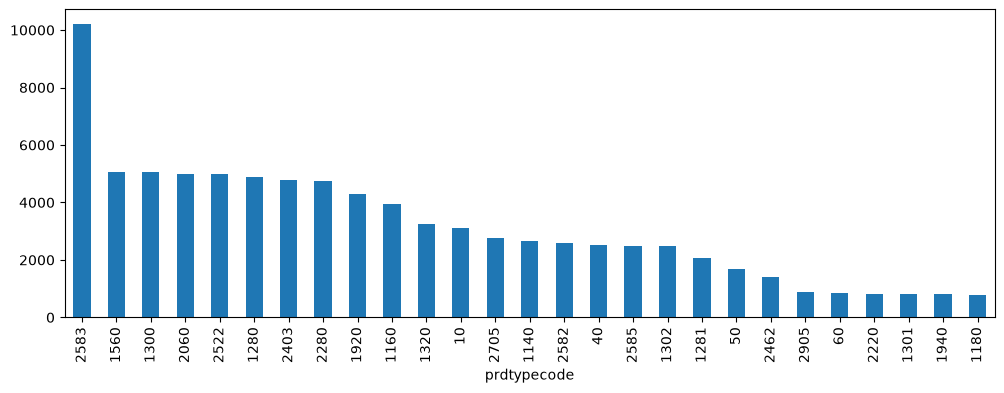

In [28]:
# nombre de catégorie et sont-elle équilibrées 

print(y_train["prdtypecode"].nunique(), "catégories")
print(y_train["prdtypecode"].value_counts(normalize=True).mul(100).round(1))
y_train["prdtypecode"].value_counts().plot(kind="bar", figsize=(12, 4));

In [29]:
Train_data = pd.concat([X_train, y_train], axis=1)

In [30]:
Train_data.head()

,designation,description,productid,imageid,prdtypecode
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046,10
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...,NaN,436067568,1008141237,2280
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo...,PILOT STYLE Touch Pen de marque Speedlink est ...,201115110,938777978,50
3,Peluche Donald - Europe - Disneyland 2000 (Mar...,NaN,50418756,457047496,1280
4,La Guerre Des Tuques,Luc a des id&eacute;es de grandeur. Il veut or...,278535884,1077757786,2705


[Text(0, 0, '97%'),
 Text(0, 0, '96%'),
 Text(0, 0, '93%'),
 Text(0, 0, '91%'),
 Text(0, 0, '89%'),
 Text(0, 0, '80%'),
 Text(0, 0, '65%'),
 Text(0, 0, '65%'),
 Text(0, 0, '37%'),
 Text(0, 0, '34%'),
 Text(0, 0, '28%'),
 Text(0, 0, '24%'),
 Text(0, 0, '24%'),
 Text(0, 0, '23%'),
 Text(0, 0, '22%'),
 Text(0, 0, '16%'),
 Text(0, 0, '13%'),
 Text(0, 0, '11%'),
 Text(0, 0, '9%'),
 Text(0, 0, '8%'),
 Text(0, 0, '8%'),
 Text(0, 0, '6%'),
 Text(0, 0, '6%'),
 Text(0, 0, '5%'),
 Text(0, 0, '3%'),
 Text(0, 0, '2%'),
 Text(0, 0, '0%')]

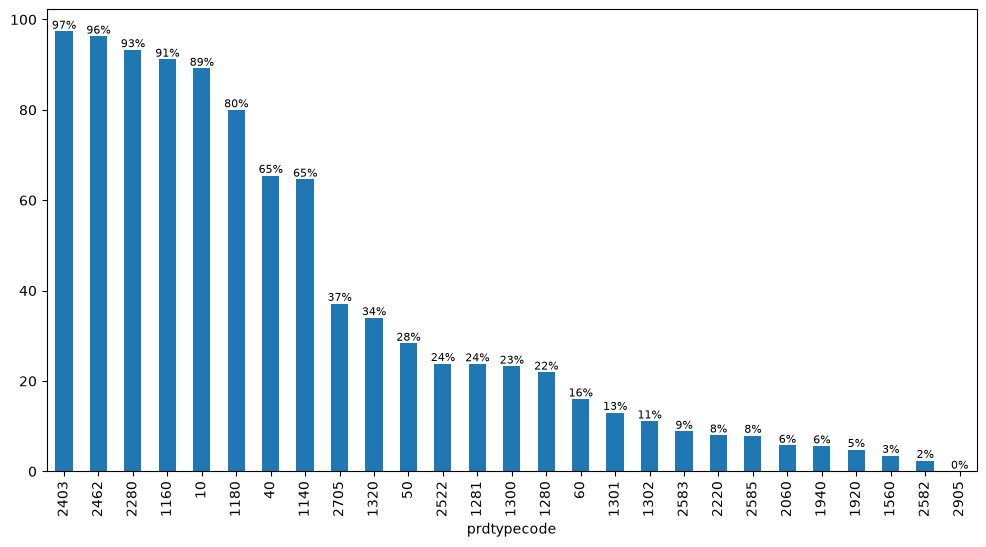

In [31]:
# description manquantes par catégorie

taux_manquant = Train_data.groupby("prdtypecode")["description"].apply(lambda x: x.isnull().mean() * 100)

plt.figure(figsize=(12, 6))
taux_manquant.sort_values(ascending=False).plot(kind="bar")
ax = taux_manquant.sort_values(ascending=False).plot(kind="bar")
ax.bar_label(ax.containers[0], fmt="%.0f%%", fontsize=8)


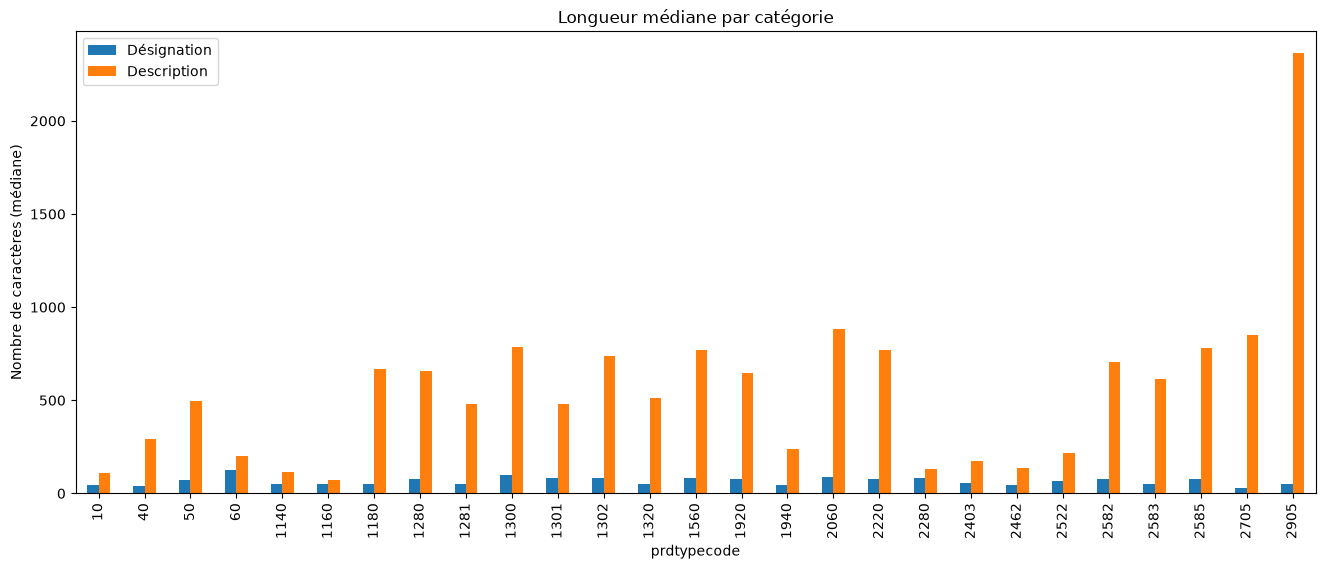

In [32]:
# longeur du texte par catégorie 

longueurs = pd.DataFrame({
    "Désignation": Train_data["designation"].str.len().groupby(Train_data["prdtypecode"]).median(),
    "Description": Train_data["description"].str.len().groupby(Train_data["prdtypecode"]).median(),
})

longueurs.plot(kind="bar", figsize=(16, 6))
plt.ylabel("Nombre de caractères (médiane)")
plt.title("Longueur médiane par catégorie");



In [33]:

def langue(texte):
    try:
        return detect(texte)
    except:
        return "inconnu"

langues = Train_data["designation"].apply(langue)

tableau = pd.crosstab(Train_data["prdtypecode"], langues, normalize="index") * 100

tableau[["fr", "en"]].plot(kind="bar", stacked=True, figsize=(16, 6))
plt.ylabel("% des produits")
plt.title("Part du français et de l'anglais par catégorie")

print(langues.value_counts().head(10))

KeyError: "None of [Index(['fr', 'en'], dtype='str', name='designation')] are in the [columns]"

In [34]:
print(langues.value_counts().head())

designation
inconnu    84916
Name: count, dtype: int64


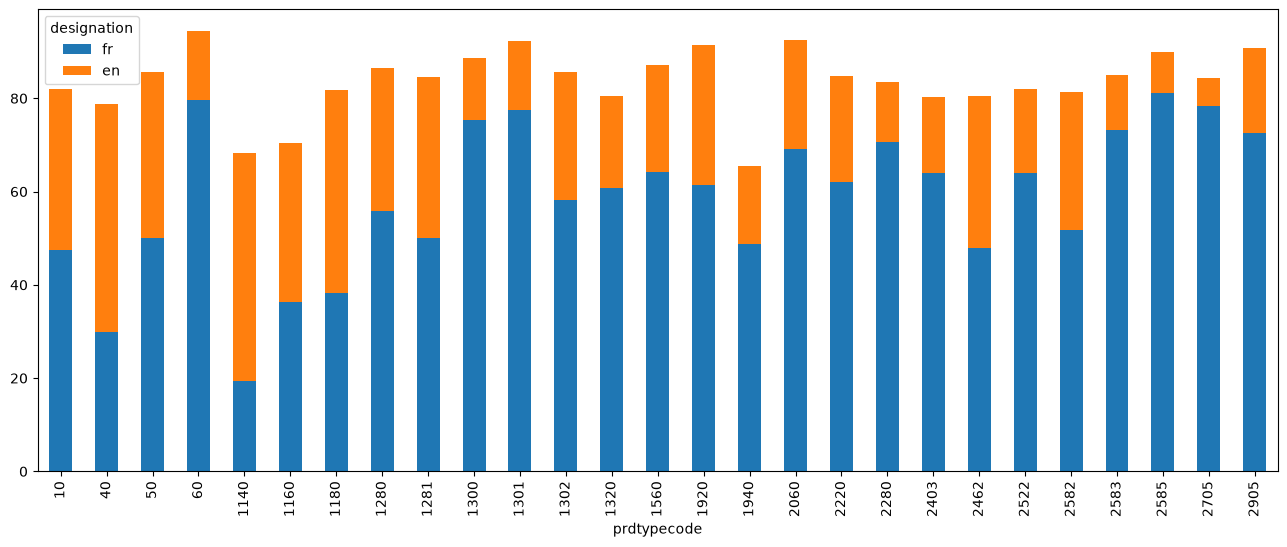

In [35]:
from langdetect import detect

def detecter_langue(texte):
    try:
        return detect(texte)
    except:
        return "inconnu"

langues_detectees = Train_data["designation"].apply(detecter_langue)

tableau = pd.crosstab(Train_data["prdtypecode"], langues_detectees, normalize="index") * 100

tableau[["fr", "en"]].plot(kind="bar", stacked=True, figsize=(16, 6));

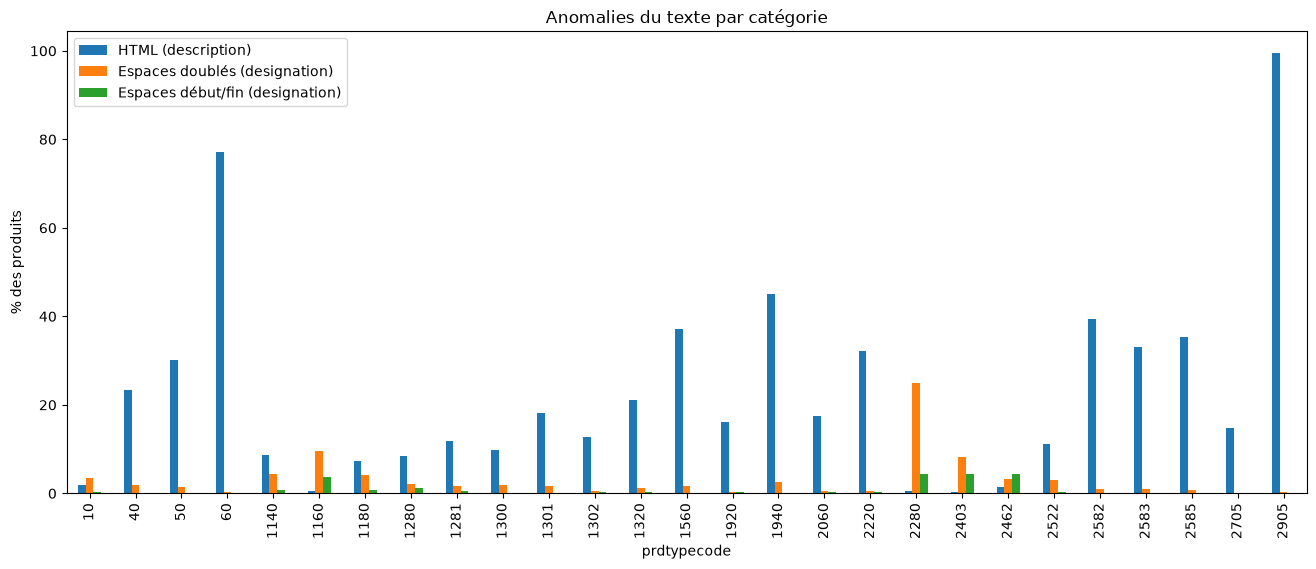

In [37]:
anomalies = pd.DataFrame({
    "HTML (description)": Train_data["description"].str.contains(r"<[^>]+>", na=False),
    "Espaces doublés (designation)": Train_data["designation"].str.contains(r" {2,}", na=False),
    "Espaces début/fin (designation)": Train_data["designation"].str.contains(r"^ | $", na=False),
}).groupby(Train_data["prdtypecode"]).mean() * 100

anomalies.plot(kind="bar", figsize=(16, 6))
plt.ylabel("% des produits")
plt.title("Anomalies du texte par catégorie");

In [ ]:
import numpy as np
import cv2 #import OpenCV
import matplotlib.pyplot as plt

In [38]:
## Vérification des fichiers dans l'archive ZIP
import zipfile

with zipfile.ZipFile("images.zip", "r") as z:
    fichiers = [f for f in z.namelist() if f.startswith("images/image_train/")]
    print("Nombre de fichiers trouvés :", len(fichiers))
    print("Exemples :", fichiers[:5])

Nombre de fichiers trouvés : 84917
Exemples : ['images/image_train/', 'images/image_train/image_1039132891_product_783203033.jpg', 'images/image_train/image_1271306830_product_3977132012.jpg', 'images/image_train/image_1282297489_product_4056046087.jpg', 'images/image_train/image_1251229442_product_3838168411.jpg']


In [39]:
images_jpg = [f for f in fichiers if f.endswith(".jpg")]
image_test = images_jpg[0]

# On lit cette image depuis le zip
with zipfile.ZipFile("images.zip", "r") as z:
    octets = np.frombuffer(z.read(image_test), np.uint8)
    
    # Équivalent exact de cv2.imread(..., cv2.IMREAD_GRAYSCALE) et cv2.IMREAD_COLOR
    img_gray = cv2.imdecode(octets, cv2.IMREAD_GRAYSCALE)
    img_color = cv2.imdecode(octets, cv2.IMREAD_COLOR)

print("Image utilisée :", image_test)
print("le type de img_gray est :", type(img_gray))
print("le type de img_color est :", type(img_color))

Image utilisée : images/image_train/image_1039132891_product_783203033.jpg
le type de img_gray est : <class 'numpy.ndarray'>
le type de img_color est : <class 'numpy.ndarray'>


In [40]:
print("Shape img_gray :", img_gray.shape)
print("Shape img_color :", img_color.shape)

Shape img_gray : (500, 500)
Shape img_color : (500, 500, 3)


In [36]:
# reverification du fichier fusionné (X_train et y_train)

Train_data.head(5)

,designation,description,productid,imageid,prdtypecode
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046,10
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...,NaN,436067568,1008141237,2280
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo...,PILOT STYLE Touch Pen de marque Speedlink est ...,201115110,938777978,50
3,Peluche Donald - Europe - Disneyland 2000 (Mar...,NaN,50418756,457047496,1280
4,La Guerre Des Tuques,Luc a des id&eacute;es de grandeur. Il veut or...,278535884,1077757786,2705


In [47]:
# échantillon des 40 images par catégorie

Train_data_sample= (Train_data.groupby('prdtypecode', group_keys=False)
    .apply(lambda x: x.sample(n=min(len(x), 40), random_state=42)))


Train_data_sample['prdtypecode'] = Train_data.loc[Train_data_sample.index, 'prdtypecode']

print("Nombre d'images échantillonnées :", len(Train_data_sample))
print("Échantillon prêt :", Train_data_sample.shape)

Nombre d'images échantillonnées : 1080
Échantillon prêt : (1080, 5)


In [48]:
Train_data_sample.head(5)

,designation,description,productid,imageid,prdtypecode
19011,Analyses Factorielles Simples Et Multiples - O...,NaN,281718,896568551,10
38665,Les Collines De L'est,NaN,62146941,893751577,10
15600,Magnétisme: Encyclopédie Magnétique Spirituali...,NaN,3374352963,1209372785,10
22220,Tom-Tom Et Nana Tome 29 - Toujours Plus Fort !,NaN,1767416,1274762387,10
24948,Denholme And The Skeleton Puzzle,NaN,418464828,1017914679,10


In [52]:
infos = []

with zipfile.ZipFile("images.zip") as z:
    for _, row in Train_data_sample.iterrows():
        nom = f"images/image_train/image_{row['imageid']}_product_{row['productid']}.jpg"
        with Image.open(z.open(nom)) as img:
            infos.append((row["prdtypecode"], img.format, img.size))

Train_data_sample_summary = pd.DataFrame(infos, columns=["categorie", "format", "taille"])
print(df_res.value_counts(["format", "taille"]))

format  taille    
JPEG    (500, 500)    1080
Name: count, dtype: int64


In [55]:
# affichage de la largeur, hauteur, résolution et ratio largeur/hauteur

infos = []

with zipfile.ZipFile("images.zip") as z:
    for _, row in Train_data_sample.iterrows():
        nom = f"images/image_train/image_{row['imageid']}_product_{row['productid']}.jpg"
        with Image.open(z.open(nom)) as img:
            largeur, hauteur = img.size
            resolution = largeur * hauteur
            ratio = largeur / hauteur if hauteur != 0 else None
            infos.append((row["prdtypecode"], img.format, largeur, hauteur, resolution, ratio))

Train_data_sample_summary = pd.DataFrame(infos, columns=["categorie", "format", "largeur", "hauteur", "resolution", "ratio"])
print(Train_data_sample_summary.value_counts(["format", "largeur", "hauteur", "resolution", "ratio"], dropna=False))






format  largeur  hauteur  resolution  ratio
JPEG    500      500      250000      1.0      1080
Name: count, dtype: int64


count    1080.00
mean       26.45
std        13.28
min         3.31
25%        16.62
50%        24.32
75%        35.29
max        77.44
Name: poids_ko, dtype: float64
images suspectes (< 3 Ko)  0


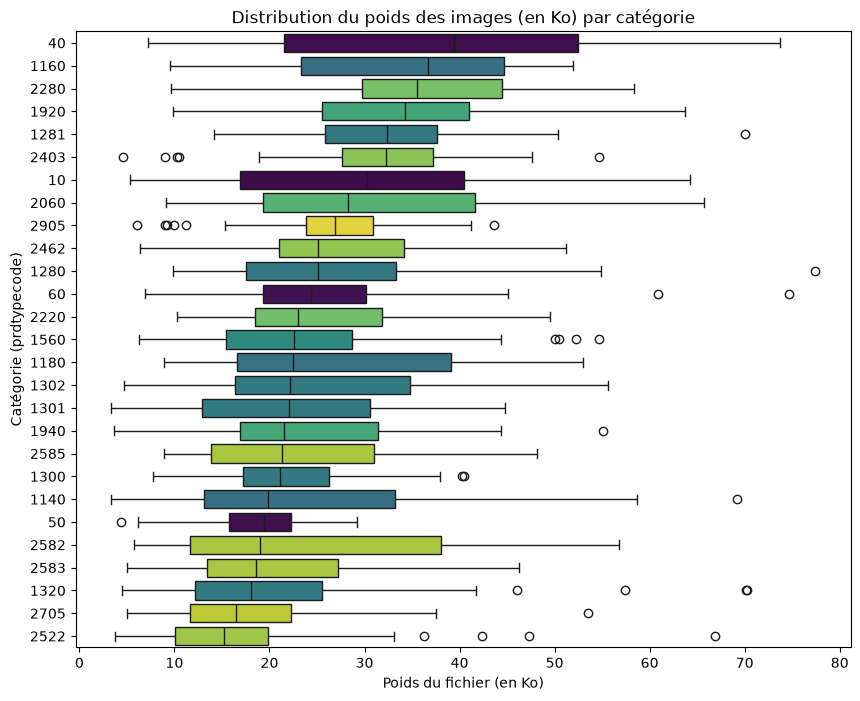

In [86]:
infos_poids = []

with zipfile.ZipFile("images.zip") as z:
    for _, row in Train_data_sample.iterrows():
        nom = f"images/image_train/image_{row['imageid']}_product_{row['productid']}.jpg"
        with z.open(nom) as f:
            poids_ko = round(len(f.read()) / 1024, 2)  # Conversion en Ko
            infos_poids.append((row["prdtypecode"], poids_ko))

Train_data_sample_summary = pd.DataFrame(infos_poids, columns=["categorie", "poids_ko"])

print(Train_data_sample_summary["poids_ko"].describe().round(2))

print("images suspectes (< 3 Ko) ", (Train_data_sample_summary["poids_ko"] < 3).sum())

ordre = Train_data_sample_summary.groupby("categorie")["poids_ko"].median().sort_values(ascending=False).index

plt.figure(figsize=(10, 8))
sns.boxplot(
    data=Train_data_sample_summary,
    x="poids_ko",
    y="categorie",
    order=ordre,
    hue="categorie",
    palette="viridis",
    legend=False,
    orient="h"
)
plt.title("Distribution du poids des images (en Ko) par catégorie")
plt.xlabel("Poids du fichier (en Ko)")
plt.ylabel("Catégorie (prdtypecode)")
plt.show()

In [72]:

with zipfile.ZipFile("images.zip") as z:
    modes = [
        Image.open(z.open(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")).mode
        for r in Train_data_sample.itertuples()
    ]

print(pd.Series(modes).value_counts())

RGB    1080
Name: count, dtype: int64


doublons  1
images presque identiques  141


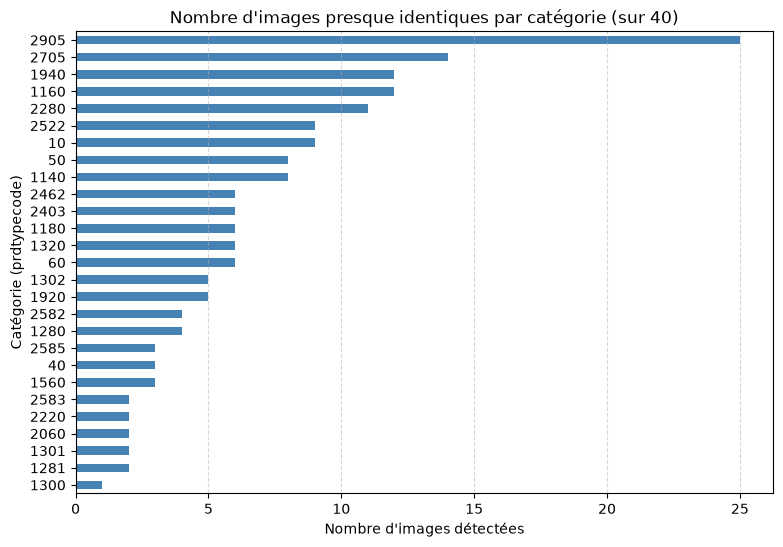

In [89]:
import hashlib, zipfile

image_identique, image_presque_identique = [], []

with zipfile.ZipFile("images.zip") as z:
    for r in Train_data_sample.itertuples():
        data = z.read(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")
        
        image_identique.append(hashlib.md5(data).hexdigest())
        
        #Image presque identique (empreinte visuelle réduite en 8x8 en noir et blanc)
        with Image.open(z.open(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")) as img:
            arr = np.array(img.convert("L").resize((8, 8)))
            image_presque_identique.append((arr > arr.mean()).tobytes())

print("doublons ", pd.Series(image_identique).duplicated().sum())
print("images presque identiques ", pd.Series(image_presque_identique).duplicated().sum())

s_similaire = pd.Series(image_presque_identique, index=Train_data_sample["prdtypecode"]).duplicated(keep=False)
par_cat = s_similaire.groupby(level=0).sum()
par_cat_positif = par_cat[par_cat > 0].sort_values(ascending=True)

plt.figure(figsize=(9, 6))
par_cat_positif.plot(kind="barh", color="steelblue")
plt.title("Nombre d'images presque identiques par catégorie (sur 40)")
plt.xlabel("Nombre d'images détectées")
plt.ylabel("Catégorie (prdtypecode)")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.show()

       luminosite  contraste
count     1080.00    1080.00
mean       195.62      64.39
std         38.80      22.54
min         14.48       8.02
25%        170.93      48.34
50%        199.44      66.10
75%        227.11      80.57
max        254.58     122.00


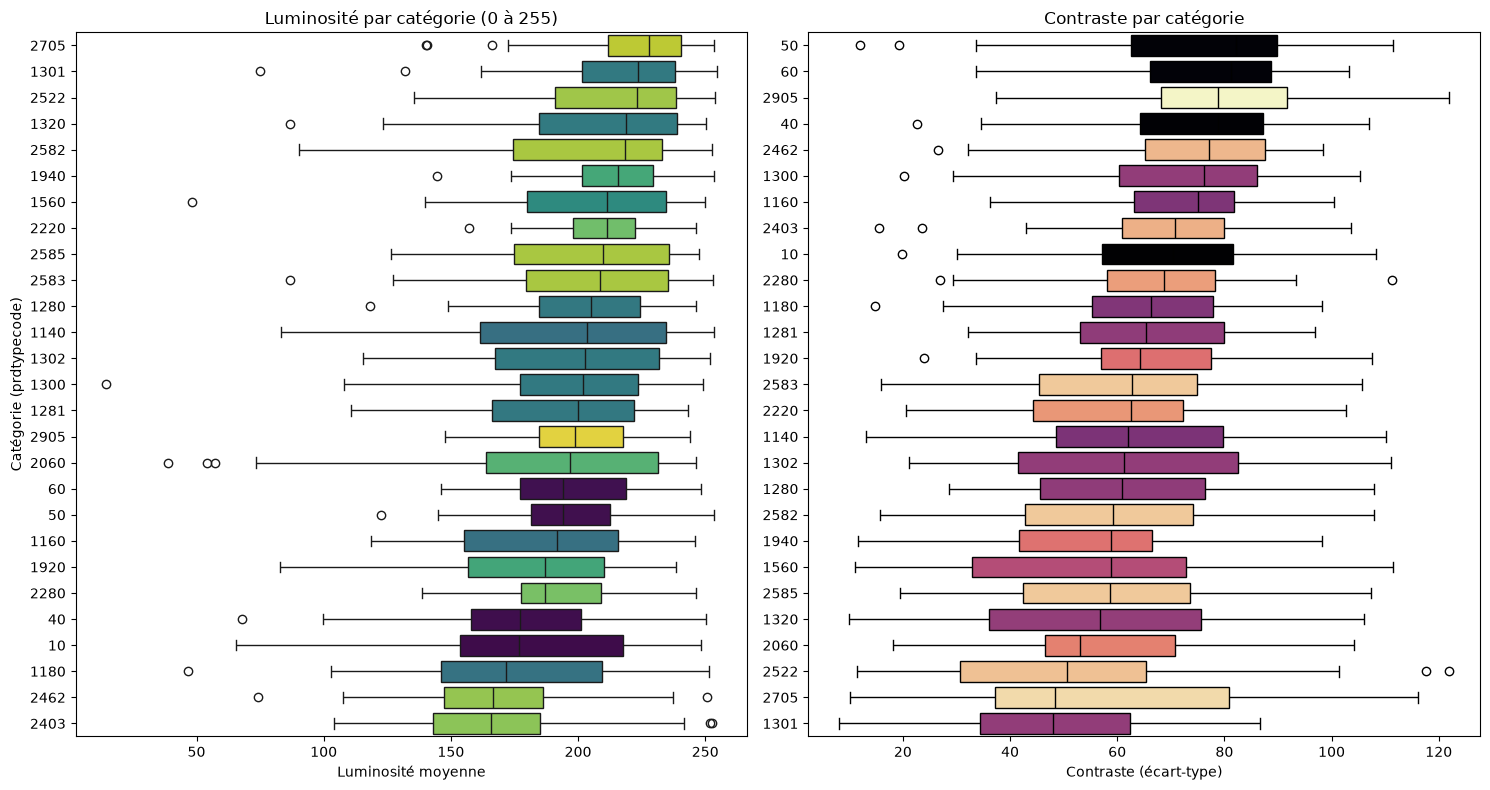

In [94]:
# analyse de la luminosité et des contrastes 

with zipfile.ZipFile("images.zip") as z:
    stats = [
        (np.array(Image.open(z.open(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")).convert("L")).mean(),
         np.array(Image.open(z.open(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")).convert("L")).std())
        for r in Train_data_sample.itertuples()
    ]

df_stats = pd.DataFrame(stats, columns=["luminosite", "contraste"]) 
df_stats["categorie"] = Train_data_sample["prdtypecode"].values

print(pd.DataFrame(stats, columns=["luminosite", "contraste"]).describe().round(2))

# graphiques 
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

ordre_lum = df_stats.groupby("categorie")["luminosite"].median().sort_values(ascending=False).index
sns.boxplot(data=df_stats, x="luminosite", y="categorie", order=ordre_lum, hue="categorie", palette="viridis", legend=False, orient="h", ax=axes[0])
axes[0].set_title("Luminosité par catégorie (0 à 255)")
axes[0].set_xlabel("Luminosité moyenne")
axes[0].set_ylabel("Catégorie (prdtypecode)")

ordre_cont = df_stats.groupby("categorie")["contraste"].median().sort_values(ascending=False).index
sns.boxplot(data=df_stats, x="contraste", y="categorie", order=ordre_cont, hue="categorie", palette="magma", legend=False, orient="h", ax=axes[1])
axes[1].set_title("Contraste par catégorie")
axes[1].set_xlabel("Contraste (écart-type)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [97]:
from PIL import ImageFilter

with zipfile.ZipFile("images.zip") as z:
    image_nette = [
        np.array(Image.open(z.open(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")).convert("L").filter(ImageFilter.FIND_EDGES)).var()
        for r in Train_data_sample.itertuples()
    ]

print(pd.Series(image_nette).describe().round(2))



count    1080.00
mean     1910.15
std      1073.57
min       230.39
25%      1100.51
50%      1642.29
75%      2465.76
max      8228.74
dtype: float64


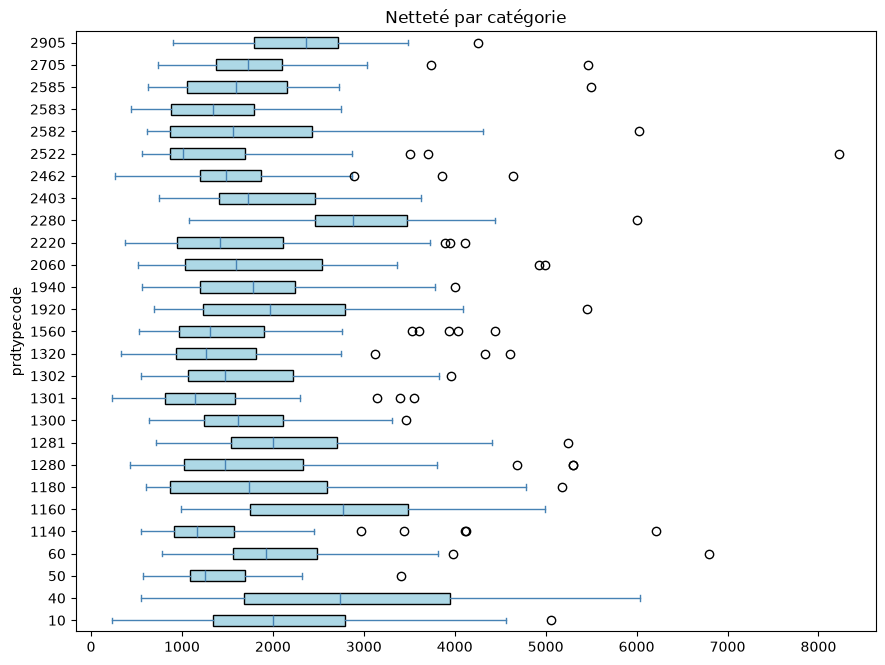

In [103]:
from PIL import ImageFilter

with zipfile.ZipFile("images.zip") as z:
    Train_data_sample["image_nette"] = [
        np.array(Image.open(z.open(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")).convert("L").filter(ImageFilter.FIND_EDGES)).var()
        for r in Train_data_sample.itertuples()
    ]

ordre = Train_data_sample.groupby("prdtypecode")["image_nette"].median().sort_values(ascending=False).index



Train_data_sample.boxplot(column="image_nette", by="prdtypecode", vert=False, figsize=(10, 8), color="steelblue", grid=False, patch_artist=True, boxprops=dict(facecolor="lightblue"))
plt.title("Netteté par catégorie")
plt.suptitle("")
plt.show()



images sous-exposées (< 60)  6
images surexposées (> 245)  80


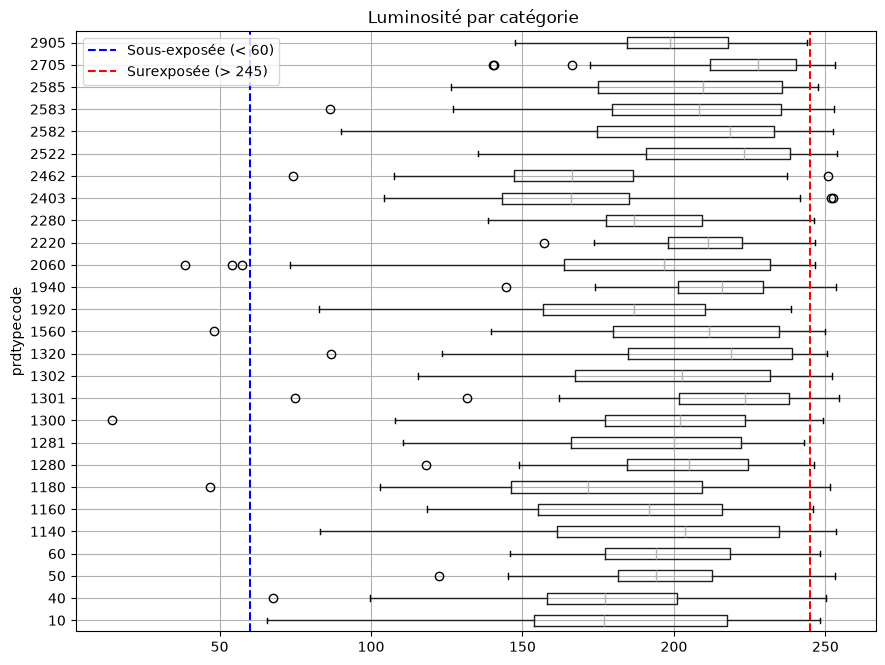

In [105]:
with zipfile.ZipFile("images.zip") as z:
    Train_data_sample["luminosite"] = [
        np.array(Image.open(z.open(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")).convert("L")).mean()
        for r in Train_data_sample.itertuples()
    ]

print("images sous-exposées (< 60) ", (Train_data_sample["luminosite"] < 60).sum())
print("images surexposées (> 245) ", (Train_data_sample["luminosite"] > 245).sum())

Train_data_sample.boxplot(column="luminosite", by="prdtypecode", vert=False, figsize=(10, 8))
plt.axvline(60, color="blue", linestyle="--", label="Sous-exposée (< 60)")
plt.axvline(245, color="red", linestyle="--", label="Surexposée (> 245)")
plt.title("Luminosité par catégorie ")
plt.suptitle("")
plt.legend()
plt.show()

count    1080.00
mean        1.82
std         1.45
min         0.05
25%         0.77
50%         1.41
75%         2.49
max         8.92
Name: bruit, dtype: float64


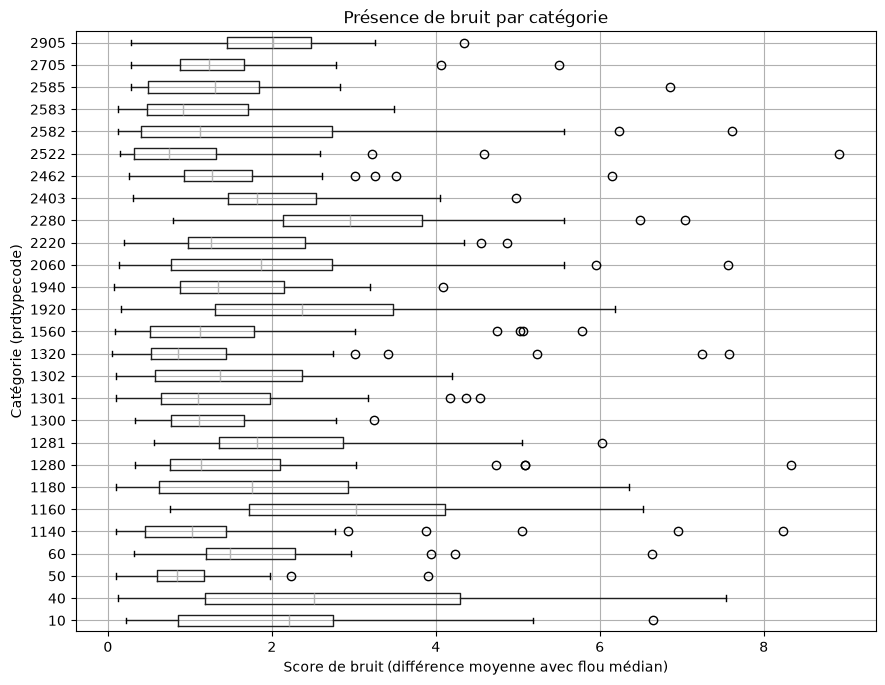

In [106]:
with zipfile.ZipFile("images.zip") as z:
    Train_data_sample["bruit"] = [
        np.abs(
            np.array(img := Image.open(z.open(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")).convert("L"), dtype=float)
            - np.array(img.filter(ImageFilter.MedianFilter(3)), dtype=float)
        ).mean()
        for r in Train_data_sample.itertuples()
    ]

print(Train_data_sample["bruit"].describe().round(2))

Train_data_sample.boxplot(column="bruit", by="prdtypecode", vert=False, figsize=(10, 8))
plt.title("Présence de bruit par catégorie")
plt.suptitle("")
plt.xlabel("Score de bruit (différence moyenne avec flou médian)")
plt.ylabel("Catégorie (prdtypecode)")
plt.show()

count    1080.00
mean       47.92
std        26.22
min         0.42
25%        26.43
50%        45.64
75%        69.42
max       100.00
Name: occupation_sujet_pct, dtype: float64


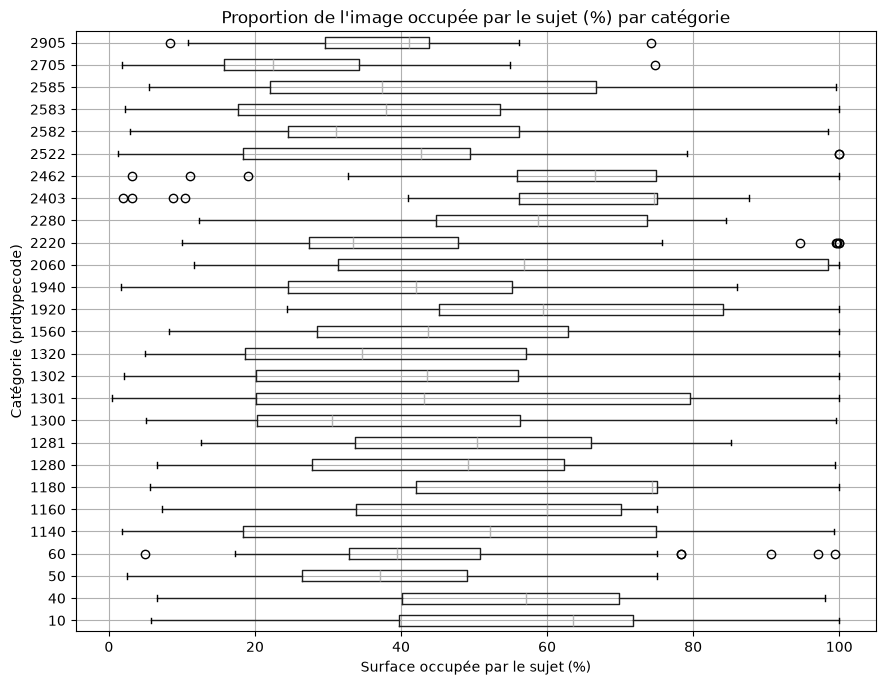

In [107]:
with zipfile.ZipFile("images.zip") as z:
    Train_data_sample["occupation_sujet_pct"] = [
        (np.array(Image.open(z.open(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")).convert("L")) < 245).mean() * 100
        for r in Train_data_sample.itertuples()
    ]

print(Train_data_sample["occupation_sujet_pct"].describe().round(2))

# Graphique par catégorie
Train_data_sample.boxplot(column="occupation_sujet_pct", by="prdtypecode", vert=False, figsize=(10, 8))
plt.title("Proportion de l'image occupée par le sujet (%) par catégorie")
plt.suptitle("")
plt.xlabel("Surface occupée par le sujet (%)")
plt.ylabel("Catégorie (prdtypecode)")
plt.show()

count    1080.00
mean       27.46
std        32.05
min         0.00
25%         0.00
50%        13.65
75%        49.74
max       118.91
Name: fond_charge, dtype: float64


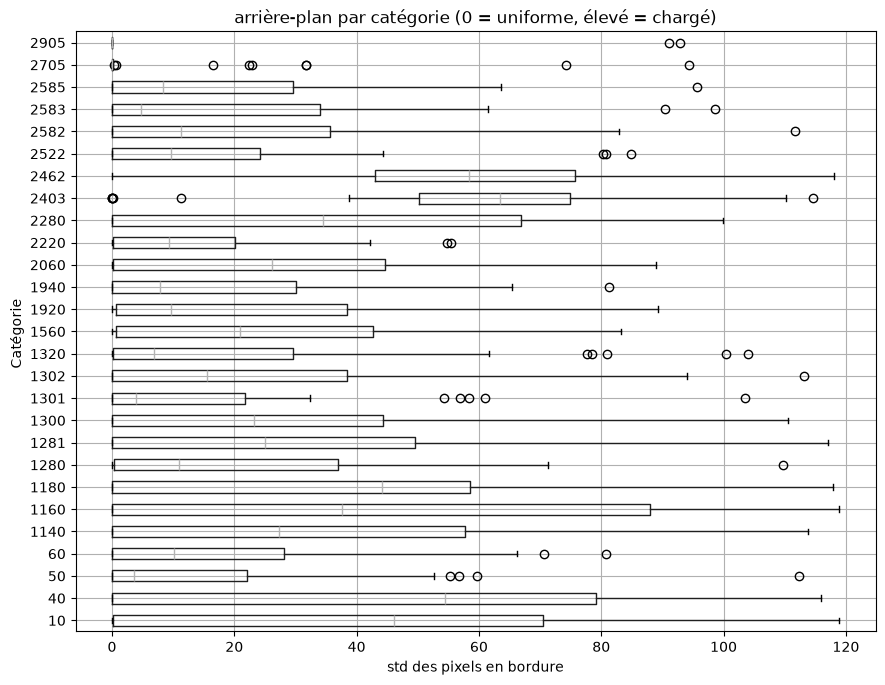

In [109]:

with zipfile.ZipFile("images.zip") as z:
    bords = []
    for r in Train_data_sample.itertuples():
        arr = np.array(Image.open(z.open(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")).convert("L"))
        cadre = np.concatenate([arr[:20, :].ravel(), arr[-20:, :].ravel(), arr[:, :20].ravel(), arr[:, -20:].ravel()])
        bords.append(cadre.std())
    Train_data_sample["fond_charge"] = bords

print(Train_data_sample["fond_charge"].describe().round(2))

Train_data_sample.boxplot(column="fond_charge", by="prdtypecode", vert=False, figsize=(10, 8))
plt.title("arrière-plan par catégorie (0 = uniforme, élevé = chargé)")
plt.suptitle("")
plt.xlabel("std des pixels en bordure")
plt.ylabel("Catégorie ")
plt.show()

In [113]:
from scipy.ndimage import label

with zipfile.ZipFile("images.zip") as z:
    nb_objets = []
    for r in Train_data_sample.itertuples():
        # Reduction en 100x100 pour ignorer les petits détails et garder les gros objets
        arr = np.array(Image.open(z.open(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")).convert("L").resize((100, 100)))
        # Compter les blocs séparés qui ne sont pas blancs (< 240)
        _, count = label(arr < 240)
        nb_objets.append(count)
    Train_data_sample["nb_objets"] = nb_objets

print(Train_data_sample["nb_objets"].describe().round(2))



count    1080.00
mean        2.99
std         5.39
min         1.00
25%         1.00
50%         1.00
75%         3.00
max        76.00
Name: nb_objets, dtype: float64


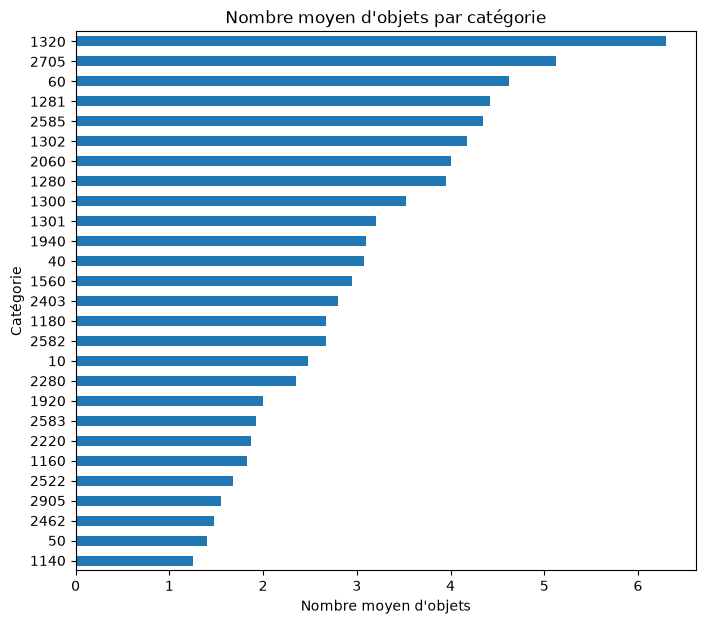

In [112]:
Train_data_sample.groupby("prdtypecode")["nb_objets"].mean().sort_values().plot(kind="barh", figsize=(8, 7))
plt.title("Nombre moyen d'objets par catégorie")
plt.xlabel("Nombre moyen d'objets")
plt.ylabel("Catégorie")
plt.show()

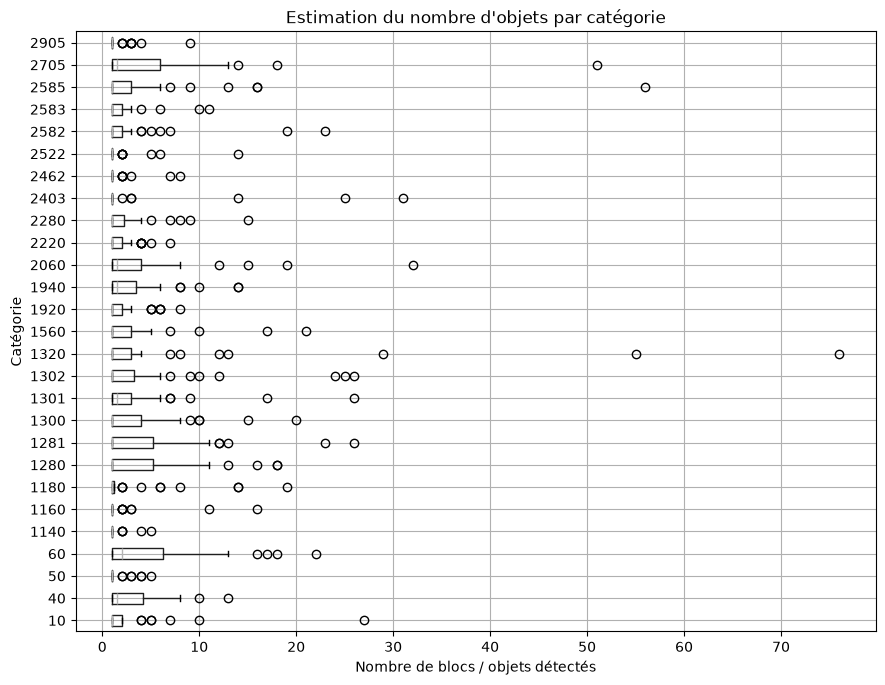

In [114]:
Train_data_sample.boxplot(column="nb_objets", by="prdtypecode", vert=False, figsize=(10, 8))
plt.title("Estimation du nombre d'objets par catégorie")
plt.suptitle("")
plt.xlabel("Nombre de blocs / objets détectés")
plt.ylabel("Catégorie")
plt.show()

count    1080.00
mean        4.62
std         3.05
min         0.34
25%         2.36
50%         3.76
75%         6.09
max        19.91
Name: score_texte, dtype: float64


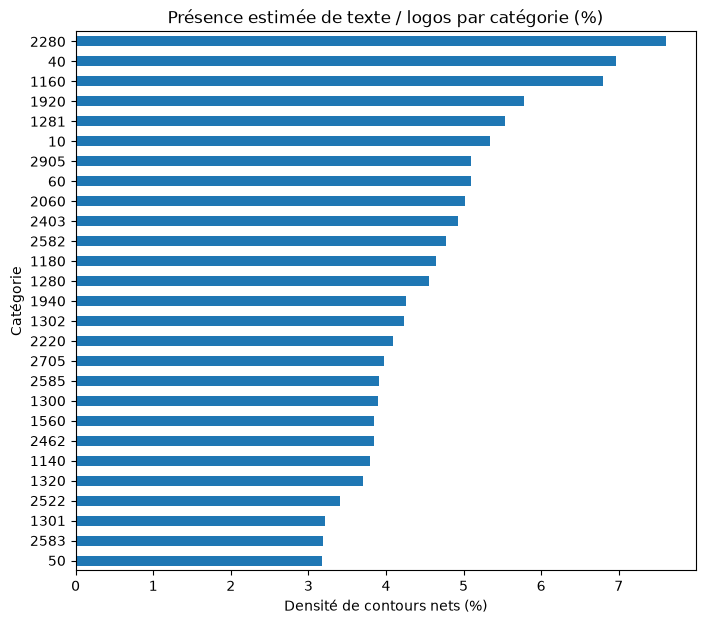

In [115]:
with zipfile.ZipFile("images.zip") as z:
    Train_data_sample["score_texte"] = [
        (np.array(Image.open(z.open(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")).convert("L").filter(ImageFilter.FIND_EDGES)) > 100).mean() * 100
        for r in Train_data_sample.itertuples()
    ]

print(Train_data_sample["score_texte"].describe().round(2))

# Graphique en barre
Train_data_sample.groupby("prdtypecode")["score_texte"].mean().sort_values().plot(kind="barh", figsize=(8, 7))
plt.title("Présence estimée de texte / logos par catégorie (%)")
plt.xlabel("Densité de contours nets (%)")
plt.ylabel("Catégorie")
plt.show()

In [ ]:
# préprocessing des images 

In [ ]:
# importer l'échantillion

import os
import io
import zipfile
from PIL import Image

DOSSIER = r"C:\Users\loud\Desktop\Rakuten\Rakuten\Datas"

# Les produits et leurs catégories
X = pd.read_csv(os.path.join(DOSSIER, "X_train_update.csv"), index_col=0)
y = pd.read_csv(os.path.join(DOSSIER, "Y_train_CVw08PX.csv"), index_col=0)
df = X.join(y)

# ouverture du ZIP (sans le décompresser) et on repère les images du train
zf = zipfile.ZipFile(os.path.join(DOSSIER, "images.zip"))
index_zip = {os.path.basename(n): n for n in zf.namelist()
             if "image_train" in n and n.endswith(".jpg")}
print(len(index_zip), "images train dans le ZIP")  

# nom de fichier de chaque image de l'échantillon
echantillon["fichier"] = [f"image_{i}_product_{p}.jpg"
                          for i, p in zip(echantillon["imageid"], echantillon["productid"])]

# lecture des 1080 images directement dans le ZIP
images = [Image.open(io.BytesIO(zf.read(index_zip[f]))).convert("RGB")
          for f in echantillon["fichier"]]
print(len(images))   

84916 images train dans le ZIP
1080


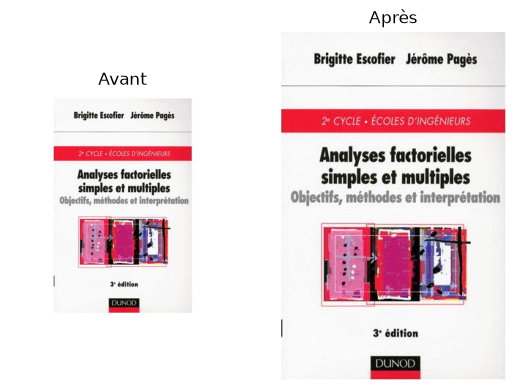

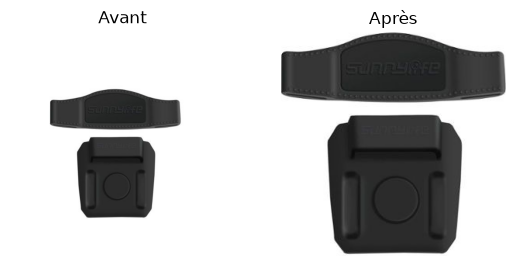

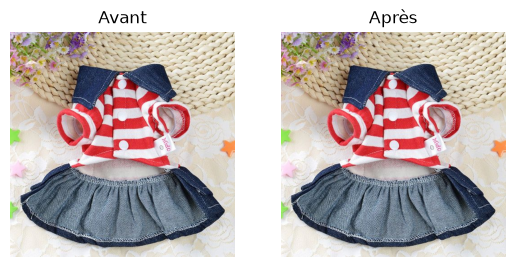

In [6]:
import matplotlib.pyplot as plt


# recadrage des images pour supprimer les marges blanches
def recadrer(img):
    # On repère ce qui n'est pas blanc (pixels sous 240)
    masque = img.convert("L").point(lambda p: 255 if p < 240 else 0)
    # On trouve le rectangle autour du produit
    boite = masque.getbbox()
    # Si l'image est toute blanche, on la laisse telle quelle
    if boite is None:
        return img
    # Sinon, on découpe
    return img.crop(boite)


images_recadrees = [recadrer(img) for img in images]

for i in [0, 300, 700]:
    plt.subplot(1, 2, 1); plt.imshow(images[i]); plt.title("Avant"); plt.axis("off")
    plt.subplot(1, 2, 2); plt.imshow(images_recadrees[i]); plt.title("Après"); plt.axis("off")
    plt.show()

1080 (224, 224)


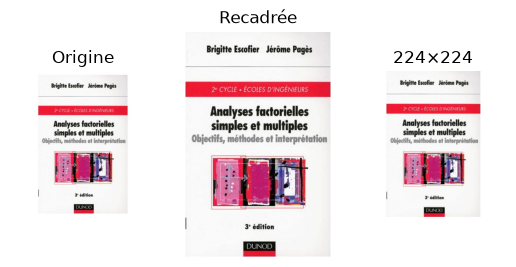

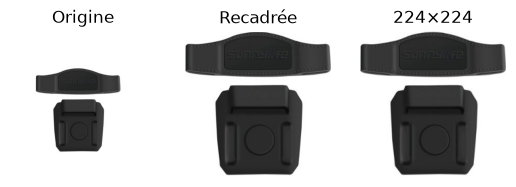

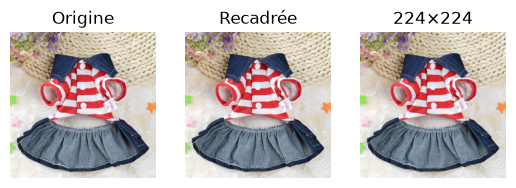

In [8]:
from PIL import ImageOps

images_taille224 = [ImageOps.pad(img, (224, 224), color="white") for img in images_recadrees]
print(len(images_taille224), images_taille224[0].size) 

for i in [0, 300, 700]:
    plt.subplot(1, 3, 1); plt.imshow(images[i]);           plt.title("Origine");  plt.axis("off")
    plt.subplot(1, 3, 2); plt.imshow(images_recadrees[i]); plt.title("Recadrée"); plt.axis("off")
    plt.subplot(1, 3, 3); plt.imshow(images_taille224[i]);       plt.title("224×224");  plt.axis("off")
    plt.show()

In [11]:
# verification de leffet du recadrage 

import numpy as np
stats_apres = [
    (np.array(img.convert("L")).mean(),
     np.array(img.convert("L")).std())
    for img in images_taille224
]
print(pd.DataFrame(stats_apres, columns=["luminosite", "contraste"]).describe().round(2))

       luminosite  contraste
count     1080.00    1080.00
mean       180.10      67.28
std         41.31      21.98
min         15.31       2.63
25%        154.15      51.59
50%        181.98      69.85
75%        213.11      83.32
max        254.20     118.53


In [12]:
# verification de la surexposition et sous-exposition des images après recadrage

echantillon["luminosite_apres"] = [np.array(img.convert("L")).mean() for img in images_taille224]

print("images sous-exposées (< 60) ", (echantillon["luminosite_apres"] < 60).sum())
print("images surexposées (> 245) ", (echantillon["luminosite_apres"] > 245).sum())

images sous-exposées (< 60)  11
images surexposées (> 245)  22


count    1080.00
mean       58.28
std        22.16
min         1.36
25%        42.27
50%        61.95
75%        73.94
max       100.00
Name: occupation_sujet_pct_apres, dtype: float64


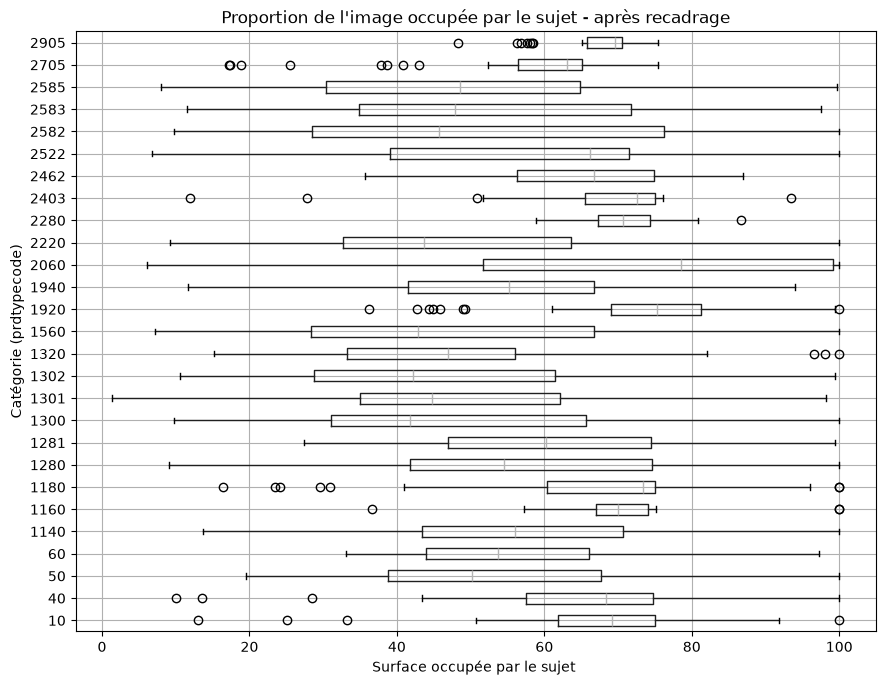

In [14]:
# Proportion du sujet APRÈS

echantillon["occupation_sujet_pct_apres"] = [
    (np.array(img.convert("L")) < 240).mean() * 100
    for img in images_taille224
]
print(echantillon["occupation_sujet_pct_apres"].describe().round(2))

echantillon.boxplot(column="occupation_sujet_pct_apres", by="prdtypecode", vert=False, figsize=(10, 8))
plt.title("Proportion de l'image occupée par le sujet - après recadrage")
plt.suptitle("")
plt.xlabel("Surface occupée par le sujet ")
plt.ylabel("Catégorie (prdtypecode)")
plt.show()

In [16]:
# application du prétraitement à toutes les images du train (100 premières pour test) avec enregistrement dans nv dossier 


with zipfile.ZipFile("images.zip") as z:
    noms = [n for n in z.namelist() if n.endswith(".jpg")]

    for n in noms:
        img = Image.open(z.open(n)).convert("RGB")            
        img = recadrer(img)                                   
        img = ImageOps.pad(img, (224, 224), color="white")    

        chemin = os.path.join("images_pretraitees", n)        
        os.makedirs(os.path.dirname(chemin), exist_ok=True)
        img.save(chemin)                                      

print("Terminé")

Terminé


In [18]:

print(len(os.listdir("images_pretraitees/images/image_train")), "images train")

84916 images train


In [19]:
import hashlib, zipfile

# Le tableau complet des produits
X = pd.read_csv("X_train_update.csv", index_col=0)
y = pd.read_csv("Y_train_CVw08PX.csv", index_col=0)
df = X.join(y)

image_identique = []

with zipfile.ZipFile("images.zip") as z:
    for r in df.itertuples():
        data = z.read(f"images/image_train/image_{r.imageid}_product_{r.productid}.jpg")
        image_identique.append(hashlib.md5(data).hexdigest())

df["md5"] = image_identique

print("doublons ", df["md5"].duplicated().sum())

doublons  5692


In [20]:
doublons = df[df["md5"].duplicated(keep=False)]
print(doublons.groupby("md5")["prdtypecode"].nunique().value_counts())

prdtypecode
1    2785
2     476
4       1
5       1
3       1
Name: count, dtype: int64


In [ ]:

# Pour chaque groupe d'images identiques, on compte le nombre de catégories différentes
nb_cat = doublons.groupby("md5")["prdtypecode"].nunique()

# 25 images de chaque catégorie pour vérification visuelle
groupes_meme = nb_cat[nb_cat == 1].index[:25]
groupes_diff = nb_cat[nb_cat > 1].index[:25]

with zipfile.ZipFile("images.zip") as z:
    for type_, liste in [("meme_categorie", groupes_meme), ("categories_differentes", groupes_diff)]:
        for num, h in enumerate(liste):
            dossier = os.path.join("verification_doublons", type_, f"groupe_{num}")
            os.makedirs(dossier, exist_ok=True)

            for r in doublons[doublons["md5"] == h].itertuples():
                nom = f"image_{r.imageid}_product_{r.productid}.jpg"
                with open(os.path.join(dossier, f"cat{r.prdtypecode}_{nom}"), "wb") as f:
                    f.write(z.read(f"images/image_train/{nom}"))

print("Terminé")

Terminé


In [1]:
df_sans_doublons = df.drop_duplicates(subset=["md5", "prdtypecode"])

print("Avant :", len(df))
print("Après :", len(df_sans_doublons))
print("Lignes retirées :", len(df) - len(df_sans_doublons))

NameError: name 'df' is not defined